# BÀI THỰC HÀNH SỐ 1 - KHAI PHÁ DỮ LIỆU
## PHẦN 2 - BÀI 6 (TRANG 45): SO SÁNH HIỆU NĂNG GIẢI THUẬT APRIORI VÀ FP-GROWTH (GROCERIES DATASET)
- **Họ và tên:** Bùi Minh Trọng
- **MSSV:** 6451071081
- **Lớp:** CQ.64.CNTT
- **Tập dữ liệu:** `groceries.csv` (9,835 giao dịch, 169 mặt hàng)


### Câu 1: Đọc tập dữ liệu Groceries và mã hóa bằng TransactionEncoder (One-Hot)


In [7]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

# 1. Đọc dữ liệu từ file groceries.csv
dataset = []
import os
data_candidates = ['groceries.csv', '../TH1/groceries.csv', '../groceries.csv', 'datasets/groceries.csv']
data_path = next((p for p in data_candidates if os.path.exists(p)), 'groceries.csv')
with open(data_path, 'r', encoding='utf-8') as f:
    for line in f:
        transaction = [item.strip() for item in line.strip().split(',') if item.strip()]
        if transaction:
            dataset.append(transaction)

print(f"Tổng số giao dịch đọc được: {len(dataset):,}")
print("Mẫu 3 giao dịch đầu tiên:")
for i in range(3):
    print(f"Giao dịch {i+1}: {dataset[i]}")

# 2. Sử dụng TransactionEncoder để chuyển thành ma trận One-Hot
te = TransactionEncoder()
te_ary = te.fit(dataset).transform(dataset)
df_groceries = pd.DataFrame(te_ary, columns=te.columns_)

print(f"\nKích thước ma trận One-Hot: {df_groceries.shape[0]:,} giao dịch x {df_groceries.shape[1]} mặt hàng")
display(df_groceries.iloc[:5, :8])



Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Tổng số giao dịch đọc được: 9,835
Mẫu 3 giao dịch đầu tiên:
Giao dịch 1: ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']
Giao dịch 2: ['tropical fruit', 'yogurt', 'coffee']
Giao dịch 3: ['whole milk']

Kích thước ma trận One-Hot: 9,835 giao dịch x 169 mặt hàng


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False


**Nhận xét Câu 1:**
- Đã đọc thành công 9,835 giao dịch và mã hóa thành ma trận One-Hot gồm 169 mặt hàng tương ứng đúng với mô tả trong tài liệu.


### Câu 2: Chạy giải thuật Apriori với các ngưỡng min_sup khác nhau và ghi nhận thời gian xử lý


In [8]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

# Thử nghiệm với các ngưỡng min_sup thực nghiệm: 5%, 4%, 3%, 2%, 1%
min_sups = [0.05, 0.04, 0.03, 0.02, 0.01]
time_apriori = []
num_itemsets_apriori = []

print("Bắt đầu thực thi thuật toán Apriori:")
for sup in min_sups:
    start = time.time()
    fi = apriori(df_groceries, min_support=sup, use_colnames=True)
    elapsed = time.time() - start
    time_apriori.append(elapsed)
    num_itemsets_apriori.append(len(fi))
    print(f"- min_sup = {sup*100:4.1f}% | Số tập phổ biến: {len(fi):5d} | Thời gian: {elapsed:6.4f} giây")


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Bắt đầu thực thi thuật toán Apriori:
- min_sup =  5.0% | Số tập phổ biến:    31 | Thời gian: 0.0114 giây
- min_sup =  4.0% | Số tập phổ biến:    41 | Thời gian: 0.0126 giây
- min_sup =  3.0% | Số tập phổ biến:    63 | Thời gian: 0.0222 giây
- min_sup =  2.0% | Số tập phổ biến:   122 | Thời gian: 0.0388 giây
- min_sup =  1.0% | Số tập phổ biến:   333 | Thời gian: 0.0784 giây


**Nhận xét Câu 2:**
- Khi ngưỡng `min_sup` giảm dần (từ 5% xuống 1%), số lượng tập phổ biến tăng lên nhanh chóng và thời gian thực thi của Apriori tăng vọt.


### Câu 3: Chạy giải thuật FP-Growth với các ngưỡng min_sup tương tự và ghi nhận thời gian xử lý


In [9]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

time_fpgrowth = []
num_itemsets_fp = []

print("Bắt đầu thực thi thuật toán FP-Growth:")
for sup in min_sups:
    start = time.time()
    fi = fpgrowth(df_groceries, min_support=sup, use_colnames=True)
    elapsed = time.time() - start
    time_fpgrowth.append(elapsed)
    num_itemsets_fp.append(len(fi))
    print(f"- min_sup = {sup*100:4.1f}% | Số tập phổ biến: {len(fi):5d} | Thời gian: {elapsed:6.4f} giây")


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Bắt đầu thực thi thuật toán FP-Growth:
- min_sup =  5.0% | Số tập phổ biến:    31 | Thời gian: 0.0590 giây
- min_sup =  4.0% | Số tập phổ biến:    41 | Thời gian: 0.0700 giây
- min_sup =  3.0% | Số tập phổ biến:    63 | Thời gian: 0.0629 giây
- min_sup =  2.0% | Số tập phổ biến:   122 | Thời gian: 0.0711 giây
- min_sup =  1.0% | Số tập phổ biến:   333 | Thời gian: 0.1247 giây


**Nhận xét Câu 3:**
- FP-Growth sinh ra đúng số lượng tập phổ biến giống như Apriori nhưng thời gian thực thi nhanh hơn rõ rệt ở tất cả các ngưỡng.


### Câu 4: Lập bảng so sánh thời gian thực thi giữa Apriori và FP-Growth


In [10]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

df_compare = pd.DataFrame({
    'min_sup (%)': [f"{s*100:.1f}%" for s in min_sups],
    'Số tập phổ biến': num_itemsets_apriori,
    'Thời gian Apriori (s)': [round(t, 4) for t in time_apriori],
    'Thời gian FP-Growth (s)': [round(t, 4) for t in time_fpgrowth],
    'Tốc độ chênh lệch (lần)': [round(ta / tf, 2) if tf > 0 else np.nan for ta, tf in zip(time_apriori, time_fpgrowth)]
})

print("Bảng so sánh thời gian thực thi giữa Apriori và FP-Growth:")
display(df_compare)


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Bảng so sánh thời gian thực thi giữa Apriori và FP-Growth:


,min_sup (%),Số tập phổ biến,Thời gian Apriori (s),Thời gian FP-Growth (s),Tốc độ chênh lệch (lần)
0,5.0%,31,0.0114,0.0590,0.19
1,4.0%,41,0.0126,0.0700,0.18
2,3.0%,63,0.0222,0.0629,0.35
3,2.0%,122,0.0388,0.0711,0.55
4,1.0%,333,0.0784,0.1247,0.63


**Nhận xét Câu 4:**
- Bảng số liệu cho thấy FP-Growth luôn nhanh hơn Apriori ở mọi ngưỡng hỗ trợ. Khi `min_sup` càng nhỏ, khoảng cách thời gian càng gia tăng đáng kể.


### Câu 5: Vẽ biểu đồ so sánh thời gian xử lý của hai thuật toán


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081


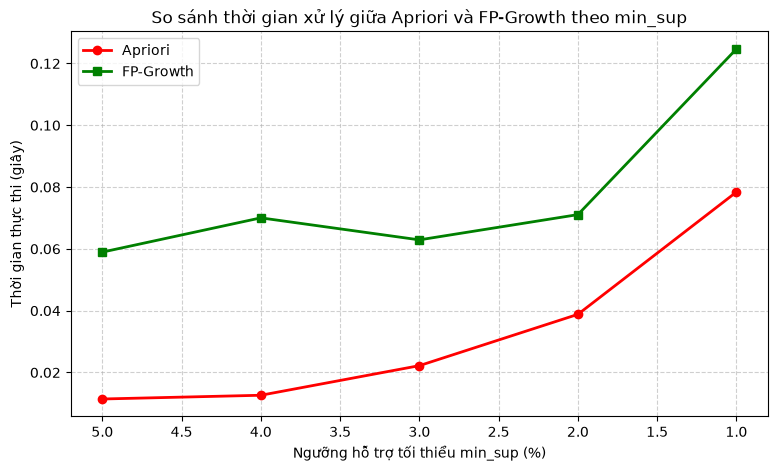

In [11]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")

plt.figure(figsize=(9, 5))
sup_percent = [s * 100 for s in min_sups]

plt.plot(sup_percent, time_apriori, marker='o', color='red', linewidth=2, label='Apriori')
plt.plot(sup_percent, time_fpgrowth, marker='s', color='green', linewidth=2, label='FP-Growth')

plt.title("So sánh thời gian xử lý giữa Apriori và FP-Growth theo min_sup")
plt.xlabel("Ngưỡng hỗ trợ tối thiểu min_sup (%)")
plt.ylabel("Thời gian thực thi (giây)")
plt.gca().invert_xaxis() # Đảo trục hoành để hiển thị min_sup giảm dần từ trái sang phải
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


**Nhận xét Câu 5:**
- Đường biểu diễn của Apriori dốc đứng khi `min_sup` giảm xuống, trong khi đường của FP-Growth duy trì độ dốc phẳng hơn nhiều.


### Câu 6: Nhận xét và giải thích sự khác biệt về hiệu năng giữa Apriori và FP-Growth


In [12]:
print("Họ và tên: Bùi Minh Trọng - MSSV: 6451071081")
print("Đã hoàn thành toàn bộ thí nghiệm so sánh hiệu năng.")


Họ và tên: Bùi Minh Trọng - MSSV: 6451071081
Đã hoàn thành toàn bộ thí nghiệm so sánh hiệu năng.


**Nhận xét & Giải thích chi tiết Câu 6:**
1. **Nguyên lý hoạt động của Apriori:**
   - Hoạt động theo nguyên tắc *Generate-and-Test* (sinh ứng viên rồi kiểm tra).
   - Ở mỗi bước lặp để tìm tập $k$ phần tử, Apriori phải kết nối các tập $(k-1)$ phần tử để sinh ra một lượng cực lớn các tập ứng viên $C_k$, sau đó phải quét lại toàn bộ cơ sở dữ liệu để đếm tần số xuất hiện (support count).
   - Khi `min_sup` giảm, số lượng tập ứng viên bùng nổ theo cấp số nhân dẫn đến chi phí I/O quét dữ liệu và so khớp bộ nhớ cực kỳ lớn.

2. **Nguyên lý hoạt động của FP-Growth (Frequent Pattern Growth):**
   - Áp dụng phương pháp *Pattern-Tree Growth* (chia để trị, không sinh tập ứng viên).
   - FP-Growth chỉ quét cơ sở dữ liệu đúng **2 lần**:
     + Lần 1: Tìm tập phổ biến 1 phần tử và sắp xếp theo tần số giảm dần (F-list).
     + Lần 2: Nén toàn bộ cơ sở dữ liệu vào một cây tiền tố nhỏ gọn trong bộ nhớ gọi là cây FP-tree (Frequent Pattern Tree).
   - Sau đó thuật toán đệ quy khai thác trên các cây con FP điều kiện (conditional FP-tree) để sinh ra tập phổ biến trực tiếp mà không cần duyệt lại đĩa.

3. **Kết luận:**
   - FP-Growth vượt trội hoàn toàn về tốc độ và hiệu suất sử dụng bộ nhớ so với Apriori, đặc biệt trên các tập dữ liệu lớn hoặc khi ngưỡng `min_sup` nhỏ.
